# Data cleaning of the rental listings

**Input:** `data/data_processed/flatfox_rentals_zentralschweiz.csv` (from `data_engineering_real_estate.ipynb`: merged scraping runs, municipality assignment, municipal indicators)

**Output:**
- `data/data_processed/flatfox_rentals_clean.csv` – cleaned analysis sample
- `data/data_processed/flatfox_rentals_excluded.csv` – every removed listing with its reason (for documentation)

**Target variable:** monthly **net rent** (as defined in the feasibility study) and the net rent per m² derived from it.

The notebook follows the six mandatory steps of the project description:

1. Missing values and duplicates
2. Data types
3. Value ranges (plausibility)
4. Outliers
5. Enrichment with additional columns
6. Format for the analysis

Beforehand, the sample is restricted to unfurnished, non-temporary rental apartments with a monthly price, because the research questions concern apartments. The input contains all listings in Central Switzerland (including sales, commercial units and parking spaces). All filters based on listing characteristics are applied in this notebook.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "scripts" else Path.cwd()
DATA_DIR = PROJECT_DIR / "data" / "data_processed"
INPUT_FILE = DATA_DIR / "flatfox_rentals_zentralschweiz.csv"
OUTPUT_FILE = DATA_DIR / "flatfox_rentals_clean.csv"
EXCLUDED_FILE = DATA_DIR / "flatfox_rentals_excluded.csv"
PLZ_FILE = PROJECT_DIR / "data" / "geodata" / "ortschaftenverzeichnis_plz.csv"

CENTRAL_CANTONS = ["LU", "UR", "SZ", "OW", "NW", "ZG"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

raw = pd.read_csv(INPUT_FILE, low_memory=False)
# Reference year for the building age and the plausible year built: end of the data collection.
REFERENCE_YEAR = pd.to_datetime(raw["last_seen_at"], utc=True).dt.year.max()

print(f"Loaded: {len(raw)} listings, {raw.shape[1]} columns, reference year {REFERENCE_YEAR}")

Loaded: 2640 listings, 156 columns, reference year 2026


In [2]:
excluded = []
log = [("Initial dataset", len(raw))]


def exclude(df, mask, step, reason):
    # Removes the rows selected by the mask and logs them.
    mask = mask.fillna(False)
    removed = df.loc[mask, ["pk", "gemeinde_name", "kanton_geo", "object_type", "surface_living", "number_of_rooms"]].copy()
    removed["step"] = step
    removed["reason"] = reason
    excluded.append(removed)
    kept = df.loc[~mask].copy()
    log.append((f"{step}: {reason}", len(kept)))
    print(f"{step} – {reason}: {mask.sum()} removed, {len(kept)} remaining")
    return kept

## Restriction to rental apartments

The input contains all listings in Central Switzerland. Only rental apartments that are comparable with the regular rental market are relevant for the research questions:

| Criterion | Removed | Reason |
|---|---|---|
| Offer type | sales | purchase prices are not comparable with rents |
| Object type | commercial units, parking spaces, shared rooms, houses | not comparable with apartments |
| Furnishing | furnished apartments (`is_furnished` or object type `FURNISHED_FLAT`) | the rent includes the furniture |
| Duration | temporary offers (`is_temporary`) | often sublets at special prices |
| Price unit | everything except a monthly price | e.g. annual price per m² for commercial space |
| Coordinates | listings whose postal code belongs to a different canton than the coordinates | municipality and municipal indicators would be wrong |

**Coordinate check:** The municipality is determined from the coordinates in `data_engineering_real_estate.ipynb`. Some listings have coordinates that do not match the stated address (e.g. address in Pratteln BL, coordinates in Lucerne). We therefore compare the canton of the coordinates with the cantons of the postal code according to the official swisstopo postal code directory (`data/geodata/ortschaftenverzeichnis_plz.csv`). The comparison is done at canton level rather than municipality level, because postal code areas often extend across municipal boundaries. Listings with a postal code that is missing from the directory (e.g. 6000 Luzern) are not removed.

In [3]:
display(raw["object_type"].value_counts().rename("count").to_frame())

APARTMENT_TYPES = ["APARTMENT", "ATTIC_FLAT", "DUPLEX", "ROOF_FLAT", "STUDIO", "LOFT", "TERRACE_FLAT"]

# Cantons per postal code; a postal code can belong to several cantons.
plz = pd.read_csv(PLZ_FILE, sep=";", encoding="utf-8-sig")
cantons_by_plz = plz.groupby("PLZ4")["Kantonskürzel"].agg(set)
listing_plz_cantons = pd.to_numeric(raw["zipcode"], errors="coerce").map(cantons_by_plz)
plz_mismatch = pd.Series(
    [isinstance(cantons, set) and canton not in cantons
     for canton, cantons in zip(raw["kanton_geo"], listing_plz_cantons)],
    index=raw.index,
)

df = exclude(raw, raw["offer_type"].ne("RENT"), "0 Scope", "not a rental offer (sale)")
df = exclude(df, ~df["object_type"].isin(APARTMENT_TYPES + ["FURNISHED_FLAT"]), "0 Scope", "not an apartment (commercial, parking, shared room, house)")
df = exclude(df, df["is_furnished"].eq(True) | df["object_type"].eq("FURNISHED_FLAT"), "0 Scope", "furnished")
df = exclude(df, df["is_temporary"].eq(True), "0 Scope", "temporary")
df = exclude(df, df["price_unit"].ne("monthly"), "0 Scope", "no monthly price")

display(df.loc[plz_mismatch.loc[df.index], ["pk", "street", "zipcode", "city", "gemeinde_name", "kanton_geo"]])
df = exclude(df, plz_mismatch.loc[df.index], "0 Scope", "postal code does not match the canton of the coordinates")

apartments = df.copy()

,count
object_type,
APARTMENT,980
OFFICE,387
SHARED_FLAT,273
GARAGE_SLOT,185
COMMERCIAL,155
FURNISHED_FLAT,123
OPEN_SLOT,107
SINGLE_HOUSE,67
SHOP,47


0 Scope – not a rental offer (sale): 164 removed, 2476 remaining
0 Scope – not an apartment (commercial, parking, shared room, house): 1382 removed, 1094 remaining
0 Scope – furnished: 261 removed, 833 remaining
0 Scope – temporary: 7 removed, 826 remaining
0 Scope – no monthly price: 0 removed, 826 remaining


,pk,street,zipcode,city,gemeinde_name,kanton_geo
783,86302188,Birchweidweg 5,8707,Uetikon am See,Freienbach,SZ
1405,86418686,Burgmatt 1,6402,Merlischachen,Baar,ZG
1880,86460257,Floraweg 2,4133,Pratteln,Luzern,LU
2230,86485100,Floraweg 2,4133,Pratteln,Luzern,LU
2569,86513955,Floraweg 2,4133,Pratteln,Luzern,LU


0 Scope – postal code does not match the canton of the coordinates: 5 removed, 821 remaining


## Missing values and duplicates

### Net rent
The net rent is not stated directly in every listing. Where it is missing but the gross rent and the service charges are available, it is calculated: **net rent = gross rent − service charges**. Listings for which no net rent can be determined are removed. Missing values are not imputed, because the rent is our target variable.

### Living area and number of rooms
Without the living area the rent per m² cannot be calculated, and without the number of rooms a control variable of the analysis is missing. These listings are removed as well and not imputed.

In [4]:
key_columns = ["rent_net", "rent_gross", "rent_charges", "surface_living", "number_of_rooms",
               "floor", "year_built", "year_renovated", "price_display"]
missing = pd.DataFrame({
    "missing": df[key_columns].isna().sum(),
    "missing (%)": df[key_columns].isna().mean().mul(100).round(1),
})
missing

,missing,missing (%)
rent_net,327,39.8
rent_gross,162,19.7
rent_charges,253,30.8
surface_living,102,12.4
number_of_rooms,1,0.1
floor,160,19.5
year_built,459,55.9
year_renovated,633,77.1
price_display,7,0.9


In [5]:
df["rent_net_source"] = np.where(df["rent_net"].notna(), "reported", None)
derived = df["rent_net"].isna() & df["rent_gross"].notna() & df["rent_charges"].notna()
df.loc[derived, "rent_net"] = df.loc[derived, "rent_gross"] - df.loc[derived, "rent_charges"]
df.loc[derived, "rent_net_source"] = "derived (gross − charges)"

print(df["rent_net_source"].value_counts(dropna=False))

df = exclude(df, df["rent_net"].isna(), "1 Missing values", "net rent cannot be determined")
df = exclude(df, df["surface_living"].isna(), "1 Missing values", "no living area")
df = exclude(df, df["number_of_rooms"].isna(), "1 Missing values", "no number of rooms")

rent_net_source
reported                     494
NaN                          237
derived (gross − charges)     90
Name: count, dtype: int64
1 Missing values – net rent cannot be determined: 237 removed, 584 remaining
1 Missing values – no living area: 53 removed, 531 remaining
1 Missing values – no number of rooms: 0 removed, 531 remaining


How much the sample shrinks per canton because of the net rent matters for the interpretation (especially for Uri, Obwalden and Nidwalden):

In [6]:
before = apartments["kanton_geo"].value_counts()
after = df["kanton_geo"].value_counts()
pd.DataFrame({"apartments": before, "with net rent": after}).reindex(CENTRAL_CANTONS).fillna(0).astype(int)

,apartments,with net rent
kanton_geo,,
LU,581,375
UR,17,9
SZ,109,79
OW,18,10
NW,14,10
ZG,82,48


### Municipal indicators
The social assistance rate is missing for some small municipalities. These listings are not removed, because all other information is available. They drop out automatically in analyses that use the social assistance rate.

In [7]:
indicator_columns = ["income_median_chf", "population_growth_pct", "population_density_productive",
                     "household_size_mean", "vacancy_rate_pct", "social_assistance_rate_pct",
                     "population_age65plus_pct", "employment_per_100_residents",
                     "new_dwellings_per_1000_residents", "single_family_buildings_pct",
                     "foreign_population_pct", "net_migration_per_1000_residents"]
df[indicator_columns].isna().sum().rename("missing values").to_frame()

,missing values
income_median_chf,0
population_growth_pct,0
population_density_productive,0
household_size_mean,0
vacancy_rate_pct,0
social_assistance_rate_pct,5
population_age65plus_pct,0
employment_per_100_residents,0
new_dwellings_per_1000_residents,0
single_family_buildings_pct,0


### Duplicates
The listing ID (`pk`) is already unique after the merge. However, the same apartment can be listed again under a new ID. A listing counts as a duplicate if

- municipality, street, living area, number of rooms and floor match another listing and
- the other listing only appears after this one has disappeared.

The newest listing is kept, because it contains the current price. The rent is deliberately not part of the comparison, so that relistings with a changed price are also detected.

If two listings were online at the same time, they are different apartments (e.g. identical floor plans in the same new building) and both are kept. Listings without a street or with the placeholder "Auf Anfrage" (on request) are not compared, because municipality, area and number of rooms alone do not identify an apartment.

In [8]:
assert df["pk"].is_unique, "pk is not unique"

dup_key = ["gemeinde_bfs", "street", "surface_living", "number_of_rooms", "floor"]
df = df.sort_values(["first_seen_at", "pk"], kind="stable")

# "Auf Anfrage" is a placeholder and does not identify an apartment.
street_known = df["street"].notna() & df["street"].ne("Auf Anfrage")
known = df.loc[street_known]

# Duplicate: the next occurrence of the same apartment only appears after this listing has disappeared.
next_first_seen = known.groupby(dup_key, dropna=False)["first_seen_at"].shift(-1)
is_dup = next_first_seen.gt(known["last_seen_at"]).reindex(df.index, fill_value=False)

display(known[known.duplicated(subset=dup_key, keep=False)]
        .sort_values(dup_key + ["first_seen_at"])
        [["pk", "gemeinde_name", "street", "surface_living", "number_of_rooms", "floor", "rent_net", "first_seen_at", "last_seen_at"]]
        .assign(removed=lambda t: t.index.isin(is_dup[is_dup].index)))

df = exclude(df, is_dup, "1 Duplicates", "same apartment under a new ID")

,pk,gemeinde_name,street,surface_living,number_of_rooms,floor,rent_net,first_seen_at,last_seen_at,removed
1821,86456070,Kriens,Schachenstrasse 45,77.0,4.5,1.0,1490.0,2026-10-18T12:14:52.635701Z,2026-10-22T15:35:15.050865Z,True
2159,86479687,Kriens,Schachenstrasse 45,77.0,4.5,1.0,1490.0,2026-10-24T08:49:29.632207Z,2026-10-24T09:39:01.857255Z,False
230,85820071,Luzern,Weinmarkt 11,71.0,2.5,5.0,2360.0,2026-10-18T12:14:52.635701Z,2026-10-24T09:39:01.857255Z,False
2139,86476892,Luzern,Weinmarkt 11,71.0,2.5,5.0,2360.0,2026-10-23T12:25:48.028947Z,2026-11-06T06:40:53.202825Z,False
1529,86428626,Ruswil,Wolhuserstrasse 13,141.0,4.5,2.0,2300.0,2026-10-18T12:14:52.635701Z,2026-10-18T19:11:16.940418Z,True
1972,86463610,Ruswil,Wolhuserstrasse 13,141.0,4.5,2.0,2300.0,2026-10-19T15:11:08.866230Z,2026-10-29T07:47:51.724442Z,True
2351,86497916,Ruswil,Wolhuserstrasse 13,141.0,4.5,2.0,2300.0,2026-10-30T19:03:47.670233Z,2026-11-06T06:40:53.202825Z,False
610,86225345,Hünenberg,Matten 14,122.0,4.5,1.0,3630.0,2026-10-18T12:14:52.635701Z,2026-10-29T07:47:51.724442Z,True
2393,86502034,Hünenberg,Matten 14,122.0,4.5,1.0,3530.0,2026-10-30T19:03:47.670233Z,2026-11-06T06:40:53.202825Z,False


1 Duplicates – same apartment under a new ID: 4 removed, 527 remaining


## Data types

When reading from CSV, pandas does not detect all types correctly (e.g. timestamps as text, IDs as floats). We set them explicitly.

In [9]:
print("Before:")
check_columns = ["pk", "gemeinde_bfs", "number_of_rooms", "floor", "year_built", "first_seen_at",
                 "published", "is_furnished", "attribute_reported_lift", "kanton_geo", "object_type"]
display(df[check_columns].dtypes.rename("dtype").to_frame())

df["pk"] = df["pk"].astype("int64")
df["gemeinde_bfs"] = df["gemeinde_bfs"].astype("Int64")

for col in ["floor", "year_built", "year_renovated"]:
    df[col] = pd.to_numeric(df[col], errors="coerce").astype("Int64")

for col in ["rent_net", "rent_gross", "rent_charges", "surface_living", "number_of_rooms"]:
    df[col] = pd.to_numeric(df[col], errors="coerce").astype("float64")

for col in ["first_seen_at", "last_seen_at"]:
    df[col] = pd.to_datetime(df[col], utc=True)
df["published"] = pd.to_datetime(df["published"], utc=True, format="ISO8601")

bool_columns = ["is_furnished", "is_temporary"] + [c for c in df.columns if c.startswith("attribute_reported_")]
for col in bool_columns:
    df[col] = df[col].astype("boolean")

for col in ["kanton_geo", "object_type", "rent_net_source"]:
    df[col] = df[col].astype("category")

print("After:")
display(df[check_columns].dtypes.rename("dtype").to_frame())

Before:


,dtype
pk,int64
gemeinde_bfs,int64
number_of_rooms,float64
floor,float64
year_built,float64
first_seen_at,str
published,str
is_furnished,bool
attribute_reported_lift,bool
kanton_geo,str


After:


,dtype
pk,int64
gemeinde_bfs,Int64
number_of_rooms,float64
floor,Int64
year_built,Int64
first_seen_at,"datetime64[us, UTC]"
published,"datetime64[us, UTC]"
is_furnished,boolean
attribute_reported_lift,boolean
kanton_geo,category


## Value ranges

We check whether the values lie in a plausible range. The limits are deliberately generous; they are only meant to catch obvious data entry errors. Unusual but possible values are handled in the next step (outliers).

| Variable | Plausible range | Reason | Treatment |
|---|---|---|---|
| Living area | ≥ 20 m² | smaller units are rooms, not apartments | remove listing |
| Area per room | ≥ 8 m² | smaller values indicate an input error | remove listing |
| Net rent | > 0 and > service charges | service charges higher than the rent are implausible | remove listing |
| Number of rooms | 1–10 | | remove listing |
| Floor | −1 to 30 | the tallest residential buildings in the region have < 30 floors; 99 is a placeholder | set value to missing |
| Year built | 1500 to `REFERENCE_YEAR` + 1 | from old-town buildings to new buildings under construction | set value to missing |
| Coordinates | within Central Switzerland | already checked during the municipality assignment | – |

`REFERENCE_YEAR` is the year in which the data collection ended (derived from `last_seen_at`). For floor and year built we only set the value to missing, because these variables are not central and the rest of the listing is usable.

In [10]:
display(df[["surface_living", "number_of_rooms", "rent_net", "rent_charges", "floor", "year_built"]]
        .describe().T[["min", "25%", "50%", "75%", "max"]])

df = exclude(df, df["surface_living"] < 20, "3 Value ranges", "living area < 20 m²")
df = exclude(df, df["surface_living"] / df["number_of_rooms"] < 8, "3 Value ranges", "area per room < 8 m²")
df = exclude(df, (df["rent_net"] <= 0) | (df["rent_charges"] >= df["rent_net"]), "3 Value ranges", "net rent ≤ 0 or ≤ service charges")
df = exclude(df, ~df["number_of_rooms"].between(1, 10), "3 Value ranges", "number of rooms outside 1–10")

bad_floor = ~df["floor"].between(-1, 30) & df["floor"].notna()
bad_year = ~df["year_built"].between(1500, REFERENCE_YEAR + 1) & df["year_built"].notna()
print(f"Floor set to missing: {bad_floor.sum()} (values: {sorted(df.loc[bad_floor, 'floor'].tolist())})")
print(f"Year built set to missing: {bad_year.sum()}")
df.loc[bad_floor, "floor"] = pd.NA
df.loc[bad_year, "year_built"] = pd.NA

,min,25%,50%,75%,max
surface_living,10.0,66.0,85.0,106.0,440.0
number_of_rooms,1.0,2.5,3.5,4.5,8.0
rent_net,0.0,1555.0,1960.0,2455.0,9000.0
rent_charges,0.0,180.0,240.0,300.0,2900.0
floor,-1.0,1.0,2.0,3.0,99.0
year_built,0.0,1971.25,2012.0,2024.0,2027.0


3 Value ranges – living area < 20 m²: 4 removed, 523 remaining
3 Value ranges – area per room < 8 m²: 0 removed, 523 remaining
3 Value ranges – net rent ≤ 0 or ≤ service charges: 3 removed, 520 remaining
3 Value ranges – number of rooms outside 1–10: 0 removed, 520 remaining
Floor set to missing: 2 (values: [33, 99])
Year built set to missing: 1


## Outliers

For the outliers we look at the **net rent per m²**, because it makes apartments of different sizes comparable.

**Method:** Tukey's rule (values below Q1 − 1.5·IQR or above Q3 + 1.5·IQR), applied to the **logarithm** of the rent per m². Rents are right-skewed; without the log transformation too many expensive but genuine apartments would count as outliers.

**Treatment:** Remove. Only a few listings are affected (see table). At the lower end there are very large areas at a low rent, which points to an incorrectly recorded area (e.g. including ancillary rooms). At the upper end there are luxury or very small apartments that do not belong to the regular rental market. Such extreme values would have a disproportionate influence on the regression.

In [11]:
df["rent_net_per_m2"] = df["rent_net"] / df["surface_living"]
log_price = np.log(df["rent_net_per_m2"])

q1, q3 = log_price.quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = np.exp(q1 - 1.5 * iqr), np.exp(q3 + 1.5 * iqr)
is_outlier = ~df["rent_net_per_m2"].between(lower, upper)

print(f"Bounds: {lower:.1f} to {upper:.1f} CHF/m² per month")
display(df.loc[is_outlier, ["pk", "gemeinde_name", "object_type", "number_of_rooms", "surface_living",
                            "rent_net", "rent_net_per_m2", "short_title"]].sort_values("rent_net_per_m2"))

Bounds: 10.6 to 54.7 CHF/m² per month


,pk,gemeinde_name,object_type,number_of_rooms,surface_living,rent_net,rent_net_per_m2,short_title
755,86287981,Triengen,APARTMENT,3.5,239.0,1690.0,7.071130,3 ½ rooms apartment
929,86344230,Feusisberg,APARTMENT,4.0,140.0,1000.0,7.142857,4 rooms apartment
815,86311690,Isenthal,APARTMENT,5.5,125.0,1000.0,8.000000,5 ½ rooms apartment
1784,86453812,Kriens,APARTMENT,3.5,118.0,6500.0,55.084746,3 ½ rooms apartment
2200,86482029,Baar,APARTMENT,5.5,160.0,8850.0,55.312500,5 ½ rooms apartment
952,86351028,Cham,APARTMENT,3.5,71.0,4000.0,56.338028,3 ½ rooms apartment
2282,86488842,Luzern,APARTMENT,1.5,25.0,1460.0,58.400000,1 ½ rooms apartment
168,85535596,Schwyz,APARTMENT,1.0,20.0,1180.0,59.000000,1 room apartment
1577,86431114,Küssnacht (SZ),APARTMENT,1.0,24.0,1500.0,62.500000,1 room apartment
1192,86391520,Zug,APARTMENT,3.5,88.0,6000.0,68.181818,3 ½ rooms apartment


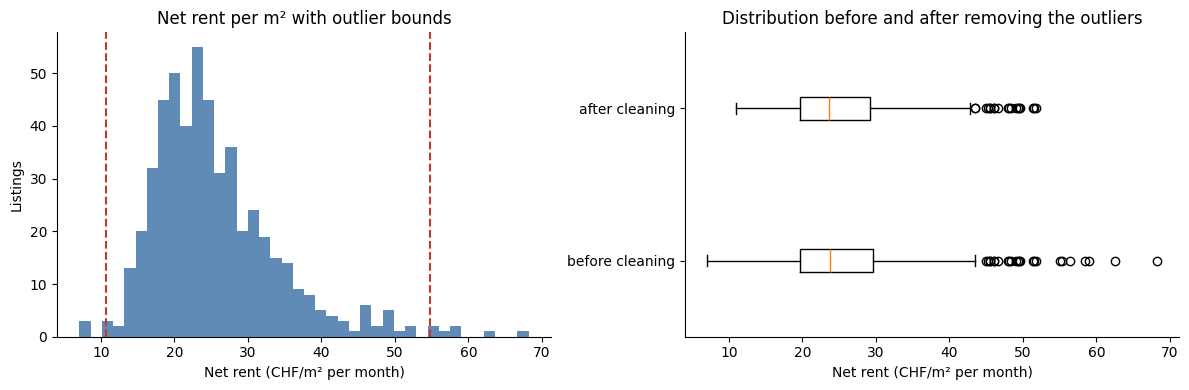

4 Outliers – net rent/m² outside 10.6–54.7 CHF: 10 removed, 510 remaining


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df["rent_net_per_m2"], bins=40, color="#3a6ea5", alpha=0.8)
for x in (lower, upper):
    axes[0].axvline(x, color="#c0392b", ls="--")
axes[0].set(title="Net rent per m² with outlier bounds", xlabel="Net rent (CHF/m² per month)", ylabel="Listings")

axes[1].boxplot([df["rent_net_per_m2"], df.loc[~is_outlier, "rent_net_per_m2"]], orientation="horizontal")
axes[1].set_yticks([1, 2], ["before cleaning", "after cleaning"])
axes[1].set(title="Distribution before and after removing the outliers", xlabel="Net rent (CHF/m² per month)")

plt.tight_layout()
plt.show()

df = exclude(df, is_outlier, "4 Outliers", f"net rent/m² outside {lower:.1f}–{upper:.1f} CHF")

*Note on the box plot:* The box plot uses the Tukey bounds on the normal scale and therefore still shows individual points above about 43 CHF/m² after cleaning. On the log scale, which we use for the outlier rule, these values lie within the bounds. They are expensive but plausible apartments (mainly in Zug and the city of Lucerne).

## Enrichment

Additional columns that are useful for the analysis:

| New column | Content |
|---|---|
| `rent_net_per_m2` | net rent per m² and month (already created in step 4) – main target variable |
| `rent_net_source` | whether the net rent was reported or derived (step 1) |
| `charges_share_pct` | share of service charges in the gross rent |
| `building_age` | years from construction or last renovation to `REFERENCE_YEAR` |
| `room_class` | room category (1–1.5, 2–2.5, 3–3.5, 4–4.5, 5+) for group comparisons |
| `population_density_log` | log of the population density (the density is highly skewed) |
| `days_online` | days between publication and last sighting (indication of demand) |

In [13]:
rent_gross_full = df["rent_gross"].fillna(df["rent_net"] + df["rent_charges"])
df["charges_share_pct"] = (df["rent_charges"] / rent_gross_full * 100).round(1)

last_year = df[["year_built", "year_renovated"]].max(axis=1)
df["building_age"] = (REFERENCE_YEAR - last_year).clip(lower=0).astype("Int64")

df["room_class"] = pd.cut(df["number_of_rooms"], bins=[0, 1.5, 2.5, 3.5, 4.5, 11],
                          labels=["1–1.5", "2–2.5", "3–3.5", "4–4.5", "5+"])

df["population_density_log"] = np.log(df["population_density_productive"])

df["days_online"] = (df["last_seen_at"] - df["published"]).dt.days

df[["rent_net_per_m2", "charges_share_pct", "building_age", "room_class", "population_density_log", "days_online"]].describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
rent_net_per_m2,510.0,NaN,NaN,NaN,25.211496,7.663116,11.0,19.677083,23.615079,29.154171,51.818182
charges_share_pct,497.0,NaN,NaN,NaN,10.61992,3.181959,0.0,8.5,10.1,12.3,28.9
building_age,340.0,<NA>,<NA>,<NA>,12.220588,17.286793,0.0,0.0,6.0,18.0,86.0
room_class,510,5,3–3.5,207,NaN,NaN,NaN,NaN,NaN,NaN,NaN
population_density_log,510.0,NaN,NaN,NaN,6.715951,1.12726,3.030134,5.806187,7.035709,8.021355,8.311988
days_online,510.0,NaN,NaN,NaN,37.462745,61.425291,0.0,6.25,17.0,42.75,548.0


## Format for the analysis

The input has more than 150 columns (all fields of the Flatfox API). For the analysis we only keep the required columns in a meaningful order: identification > rent > apartment characteristics > location > municipal indicators > data collection. The merge with the municipal indicators was already done in `data_engineering_real_estate.ipynb`.

In [14]:
FINAL_COLUMNS = [
    # Identification
    "pk", "source_url", "object_type",
    # Rent
    "rent_net", "rent_net_source", "rent_net_per_m2", "rent_charges", "rent_gross", "charges_share_pct",
    # Apartment characteristics
    "surface_living", "number_of_rooms", "room_class", "floor", "year_built", "year_renovated", "building_age",
    "attribute_reported_balconygarden", "attribute_reported_lift", "attribute_reported_view",
    "attribute_reported_parkingspace", "attribute_reported_minergie",
    # Location
    "latitude", "longitude", "gemeinde_bfs", "gemeinde_name", "kanton_geo",
    # Municipal indicators
    *indicator_columns, "population_density_log",
    # Data collection
    "published", "first_seen_at", "last_seen_at", "scrape_count", "days_online",
]

clean = (df[FINAL_COLUMNS]
         .sort_values(["kanton_geo", "gemeinde_name", "pk"])
         .reset_index(drop=True))

print(f"Clean dataset: {len(clean)} listings, {clean.shape[1]} columns, "
      f"{clean['gemeinde_bfs'].nunique()} municipalities")
clean.head()

Clean dataset: 510 listings, 44 columns, 98 municipalities


,pk,source_url,object_type,rent_net,rent_net_source,rent_net_per_m2,rent_charges,rent_gross,charges_share_pct,surface_living,...,new_dwellings_per_1000_residents,single_family_buildings_pct,foreign_population_pct,net_migration_per_1000_residents,population_density_log,published,first_seen_at,last_seen_at,scrape_count,days_online
0,86469512,https://flatfox.ch/en/flat/alemannenweg-3-6287...,APARTMENT,2250.0,derived (gross − charges),22.500000,240.0,2490.0,9.6,100.0,...,17.9,57.0,17.2,45.0,5.839769,2026-10-20 19:28:32.150576+00:00,2026-10-21 19:25:50.227446+00:00,2026-11-06 06:40:53.202825+00:00,9,16
1,86349152,https://flatfox.ch/en/flat/unterdorf-12-6147-a...,APARTMENT,1200.0,reported,14.814815,150.0,1350.0,11.1,81.0,...,0.0,50.5,13.4,-1.0,5.012633,2026-09-09 08:55:43.351266+00:00,2026-10-18 12:14:52.635701+00:00,2026-10-21 19:25:50.227446+00:00,6,42
2,86368528,https://flatfox.ch/en/flat/hintergasse-17-6147...,APARTMENT,1165.0,reported,14.382716,200.0,NaN,14.7,81.0,...,0.0,50.5,13.4,-1.0,5.012633,2026-09-16 08:45:48.023625+00:00,2026-10-18 12:14:52.635701+00:00,2026-10-24 09:39:01.857255+00:00,10,38
3,86468238,https://flatfox.ch/en/flat/unterdorf-12-6147-a...,APARTMENT,1450.0,reported,13.425926,200.0,1650.0,12.1,108.0,...,0.0,50.5,13.4,-1.0,5.012633,2026-10-20 11:46:55.045648+00:00,2026-10-20 19:12:39.840560+00:00,2026-11-06 06:40:53.202825+00:00,10,16
4,86501416,https://flatfox.ch/en/flat/6147-altburon/86501...,APARTMENT,1700.0,reported,16.190476,280.0,NaN,14.1,105.0,...,0.0,50.5,13.4,-1.0,5.012633,2026-10-30 11:36:56.960841+00:00,2026-10-30 19:03:47.670233+00:00,2026-11-06 06:40:53.202825+00:00,3,6


## Result and saving

In [15]:
summary = pd.DataFrame(log, columns=["step", "remaining listings"])
summary["removed"] = (-summary["remaining listings"].diff()).fillna(0).astype(int)
display(summary)

print("Listings and municipalities per canton:")
display(clean.groupby("kanton_geo", observed=True)
        .agg(listings=("pk", "size"), municipalities=("gemeinde_bfs", "nunique"))
        .reindex(CENTRAL_CANTONS))

,step,remaining listings,removed
0,Initial dataset,2640,0
1,0 Scope: not a rental offer (sale),2476,164
2,"0 Scope: not an apartment (commercial, parking...",1094,1382
3,0 Scope: furnished,833,261
4,0 Scope: temporary,826,7
5,0 Scope: no monthly price,826,0
6,0 Scope: postal code does not match the canton...,821,5
7,1 Missing values: net rent cannot be determined,584,237
8,1 Missing values: no living area,531,53
9,1 Missing values: no number of rooms,531,0


Listings and municipalities per canton:


,listings,municipalities
kanton_geo,,
LU,363,54
UR,8,5
SZ,76,19
OW,10,5
NW,10,5
ZG,43,10


## Validation

Before saving, a few assertions check the final dataset and the exclusion log: every listing of the input ends up either in the clean dataset or, with exactly one reason, in the excluded listings. The expected row counts are only a snapshot of the current data and trigger a warning, not an error.

In [16]:
excluded_df = pd.concat(excluded, ignore_index=True)

# Snapshot of the data collected from 18 October to 6 November 2026, not a fixed requirement.
EXPECTED_ROWS = {"input": 2640, "clean": 510}

assert clean["pk"].is_unique, "pk is not unique in the clean dataset"
assert clean[["rent_net", "surface_living", "number_of_rooms"]].notna().all().all(), "Missing rent, area or rooms"
assert np.isfinite(clean["rent_net_per_m2"]).all() and clean["rent_net_per_m2"].gt(0).all(), "rent_net_per_m2 not finite and positive"

assert len(clean) + len(excluded_df) == len(raw), "Clean + excluded listings do not add up to the input"
assert excluded_df["pk"].is_unique, "A listing was excluded more than once"
assert excluded_df[["step", "reason"]].notna().all().all(), "Excluded listing without reason"
assert set(clean["pk"]).isdisjoint(excluded_df["pk"]), "Listing both clean and excluded"
assert set(clean["pk"]) | set(excluded_df["pk"]) == set(raw["pk"]), "Listing lost during cleaning"

for name, actual in {"input": len(raw), "clean": len(clean)}.items():
    if actual != EXPECTED_ROWS[name]:
        warnings.warn(f"{name}: {actual} rows instead of {EXPECTED_ROWS[name]} (snapshot). "
                      "Update the snapshot and the interpretation texts if the data changed.")

print(f"Validation passed: {len(raw)} input = {len(clean)} clean + {len(excluded_df)} excluded "
      f"({excluded_df['reason'].nunique()} different reasons)")

Validation passed: 2640 input = 510 clean + 2130 excluded (11 different reasons)


In [17]:
OUTPUT_FILE.parent.mkdir(parents=True, exist_ok=True)
clean.to_csv(OUTPUT_FILE, index=False, encoding="utf-8-sig")
excluded_df.to_csv(EXCLUDED_FILE, index=False, encoding="utf-8-sig")

print(f"Saved: {OUTPUT_FILE.relative_to(PROJECT_DIR)} ({len(clean)} rows)")
print(f"Saved: {EXCLUDED_FILE.relative_to(PROJECT_DIR)} ({len(excluded_df)} rows)")

Saved: data/data_processed/flatfox_rentals_clean.csv (510 rows)
Saved: data/data_processed/flatfox_rentals_excluded.csv (2130 rows)
